# Person independent eye state training and evaluation

This notebook runs the real ML experiment for Driver Drowsiness Detection: dataset import,
EDA, strict person-held-out testing, training-only augmentation, GroupKFold tuning, final
refit, evaluation, and export. The functions live in `training.py` so tests and the CLI use
exactly the same code. Inspect that module to see each implementation.

The dlib `.dat` file is a pretrained facial landmark detector. This notebook trains the
HOG + SVM eye classifier; it does not retrain dlib. Eye classification scores do not measure
video-level drowsiness accuracy. No synthetic images are used as project training results.


## 0. Check the notebook environment

Use a **Python 3.11 or 3.12** kernel. The setup uses the active kernel's Python and keeps
**NumPy 1.26.4 + OpenCV 4.10.0.84** together, matching the existing Anaconda scientific libraries.
It installs packages only when they are missing or the NumPy/OpenCV versions differ.

If the kernel still holds old libraries after installation, this cell displays **Restart needed**
as normal output. Choose **Kernel → Restart Kernel**, then **Run All**. Until then the remaining
cells skip work safely. A kernel restart is necessary to clear old binary modules from memory.

With compatible packages installed and a fresh kernel, setup runs without pip or a restart.
The unrelated gensim/FuzzyTM and old Streamlit/protobuf conflicts do not affect notebook training.
Install the frontend's requirements in its project environment when running Streamlit.


In [1]:
import importlib.metadata as package_metadata
import importlib
import subprocess
import sys

ENVIRONMENT_READY = False
CONFIG_READY = (
    DATASET_READY
) = SPLIT_READY = MODEL_READY = EVALUATION_READY = EXPORT_READY = False
RUN_STATUS = "Environment check pending"
print("Notebook Python:", sys.executable)


def installed_version(distribution):
    try:
        return package_metadata.version(distribution)
    except package_metadata.PackageNotFoundError:
        return None


def prepare_environment():
    if sys.version_info[:2] not in ((3, 11), (3, 12)):
        return False, "Select a Python 3.11 or 3.12 kernel, then Run All."

    compatible_versions = {"numpy": "1.26.4", "opencv-python": "4.10.0.84"}
    training_packages = {
        "pandas": "pandas==2.2.3",
        "matplotlib": "matplotlib==3.8.4",
        "scipy": "scipy==1.11.4",
        "scikit-learn": "scikit-learn==1.5.2",
        "ipython": "ipython>=8,<10",
    }
    needs_repair = any(
        installed_version(name) != expected
        for name, expected in compatible_versions.items()
    )
    missing = [
        spec
        for name, spec in training_packages.items()
        if installed_version(name) is None
    ]
    print("Installed NumPy:", installed_version("numpy"))
    print("Installed OpenCV:", installed_version("opencv-python"))

    if needs_repair or missing:
        specs = [f"{name}=={version}" for name, version in compatible_versions.items()]
        specs.extend(missing)
        print("Installing:", ", ".join(specs))
        # Remember whether binary modules were loaded BEFORE changing their files.
        loaded = any(
            name in sys.modules
            for name in ("numpy", "cv2", "pandas", "matplotlib", "scipy", "sklearn")
        )
        result = subprocess.run(
            [sys.executable, "-m", "pip", "install", "--only-binary=:all:", *specs],
            capture_output=True,
            text=True,
        )
        if result.stdout.strip():
            print(result.stdout)
        if result.stderr.strip():
            print("Package installer notes:\n" + result.stderr)
        if result.returncode != 0:
            return (
                False,
                "Package installation did not finish. Resolve the installer message above, then rerun setup.",
            )
        importlib.invalidate_caches()
        if loaded:
            globals()["_NOTEBOOK_DEPENDENCIES_CHANGED"] = True

    loaded_numpy = sys.modules.get("numpy")
    if globals().get("_NOTEBOOK_DEPENDENCIES_CHANGED", False) or (
        loaded_numpy is not None and loaded_numpy.__version__ != "1.26.4"
    ):
        return (
            False,
            "Restart needed: choose Kernel → Restart Kernel, then Run All. The packages are installed.",
        )
    return True, "Environment ready. Compatible training dependencies are installed."


ENVIRONMENT_READY, RUN_STATUS = prepare_environment()
print(RUN_STATUS)


Notebook Python: /home/lokesh-sharma/anaconda3/bin/python
Installed NumPy: 1.26.4
Installed OpenCV: 4.10.0.84
Environment ready. Compatible training dependencies are installed.


## 1. Dataset import and experiment settings

After checking the provider's terms, download the original MRL archive from
[MRL Eye](https://mrl.cs.vsb.cz/eyedataset.html) to `data/raw/mrlEyes_2018_01.zip`.
`prepare_mrl.py` imports its filenames and metadata into `open/person_id/` and `closed/person_id/`.
MRL uses **closed=0, open=1**; the importer maps this to **open=0, closed=1** for this project.
The archive hash and source URL are stored alongside the imported data.

Custom data can use `data/eyes/open/person_id/*.png` and `closed/person_id/*.png`, or
`train/`, `validation/`, `test/` with those same class/person folders. Subject IDs must
identify people, not individual videos of the same person. Predefined train and validation
partitions form the development pool for GroupKFold; test people stay separate.
**There is no image-level split fallback.**

For a CPU-friendly initial experiment, cap development data at **100 images per person per
class**. Every retained image belonging to held-out test people is evaluated. Set the cap to
`None` for full development training; declare this change before starting a new experiment.
The cap and exact split/selection manifest are recorded with the results.


In [2]:
from pathlib import Path
import os

CONFIG_READY = (
    DATASET_READY
) = SPLIT_READY = MODEL_READY = EVALUATION_READY = EXPORT_READY = False
PROJECT_DIR = (
    Path.cwd().resolve()
)  # Set explicitly if Jupyter starts outside the project.
ROOT = next(
    (p for p in (PROJECT_DIR, *PROJECT_DIR.parents) if (p / "training.py").is_file()),
    None,
)
if not globals().get("ENVIRONMENT_READY", False):
    print("Run setup and follow its environment status first.")
elif ROOT is None:
    print("Set PROJECT_DIR to the project folder containing training.py.")
else:
    import sys
    import json
    import pandas as pd
    from IPython.display import display, Image

    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    from prepare_mrl import import_mrl
    from training import (
        scan_dataset,
        save_eda,
        split_people,
        sample_development,
        train_group_cv,
        evaluate_and_export,
    )

    DATA_DIR = Path(os.environ.get("DROWSINESS_DATA_DIR", ROOT / "data/eyes")).resolve()
    OUTPUT_DIR = Path(os.environ.get("DROWSINESS_OUTPUT_DIR", ROOT)).resolve()
    ARCHIVE = ROOT / "data/raw/mrlEyes_2018_01.zip"
    REPORT_DIR, MODEL_DIR = OUTPUT_DIR / "reports", OUTPUT_DIR / "models"
    SEED, CV_FOLDS = 42, 5
    CAP_PER_PERSON_CLASS = 100  # None uses all development images; test is always full.
    CONFIG_READY = True
    if not DATA_DIR.exists() and ARCHIVE.is_file():
        display(import_mrl(ARCHIVE, DATA_DIR))
    print("Dataset:", DATA_DIR)
    print("Development cap per person/class:", CAP_PER_PERSON_CLASS)


Dataset: /home/lokesh-sharma/Documents/Projects/Drowsiness-Detection/data/eyes
Development cap per person/class: 100


## 2. EDA and data quality

Inspect original class counts, images per person, raw brightness distributions, sample grid,
image dimensions/contrast, corrupt images, and exact duplicates. Low-contrast images are
flagged for review rather than removed, preserving difficult lighting conditions. Exact
duplicates are removed. Every copy of an exact image with conflicting labels is excluded
and recorded, without relabeling. Duplicates crossing predefined splits block training. Near-duplicate frames may remain, but every person's images stay in one partition.
MRL's infrared sensors and demographic imbalance limit generalization to RGB webcams.


,open,closed
0,42916,41911


class_name,closed,open
subject_id,,
s0001,1841,1401
s0002,1007,107
s0003,559,120
s0004,1069,0
s0005,708,28
s0006,1011,1
s0007,613,11
s0008,832,0
s0009,363,24


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
closed,41911.0,82.040736,19.757461,26.71355,68.496604,79.297830,90.283026,213.775414
open,42916.0,94.486908,30.729166,21.15623,76.787378,87.113525,101.026318,222.276130


,path,reason,excluded,duplicate_of,sha256
0,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
1,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
2,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
3,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
4,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
5,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
6,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
7,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
8,/home/lokesh-sharma/Documents/Projects/Drowsin...,low_contrast_review,False,NaN,NaN
9,/home/lokesh-sharma/Documents/Projects/Drowsin...,exact_duplicate,True,/home/lokesh-sharma/Documents/Projects/Drowsin...,788365e8760b22305644c974848224326c27dfbf299100...


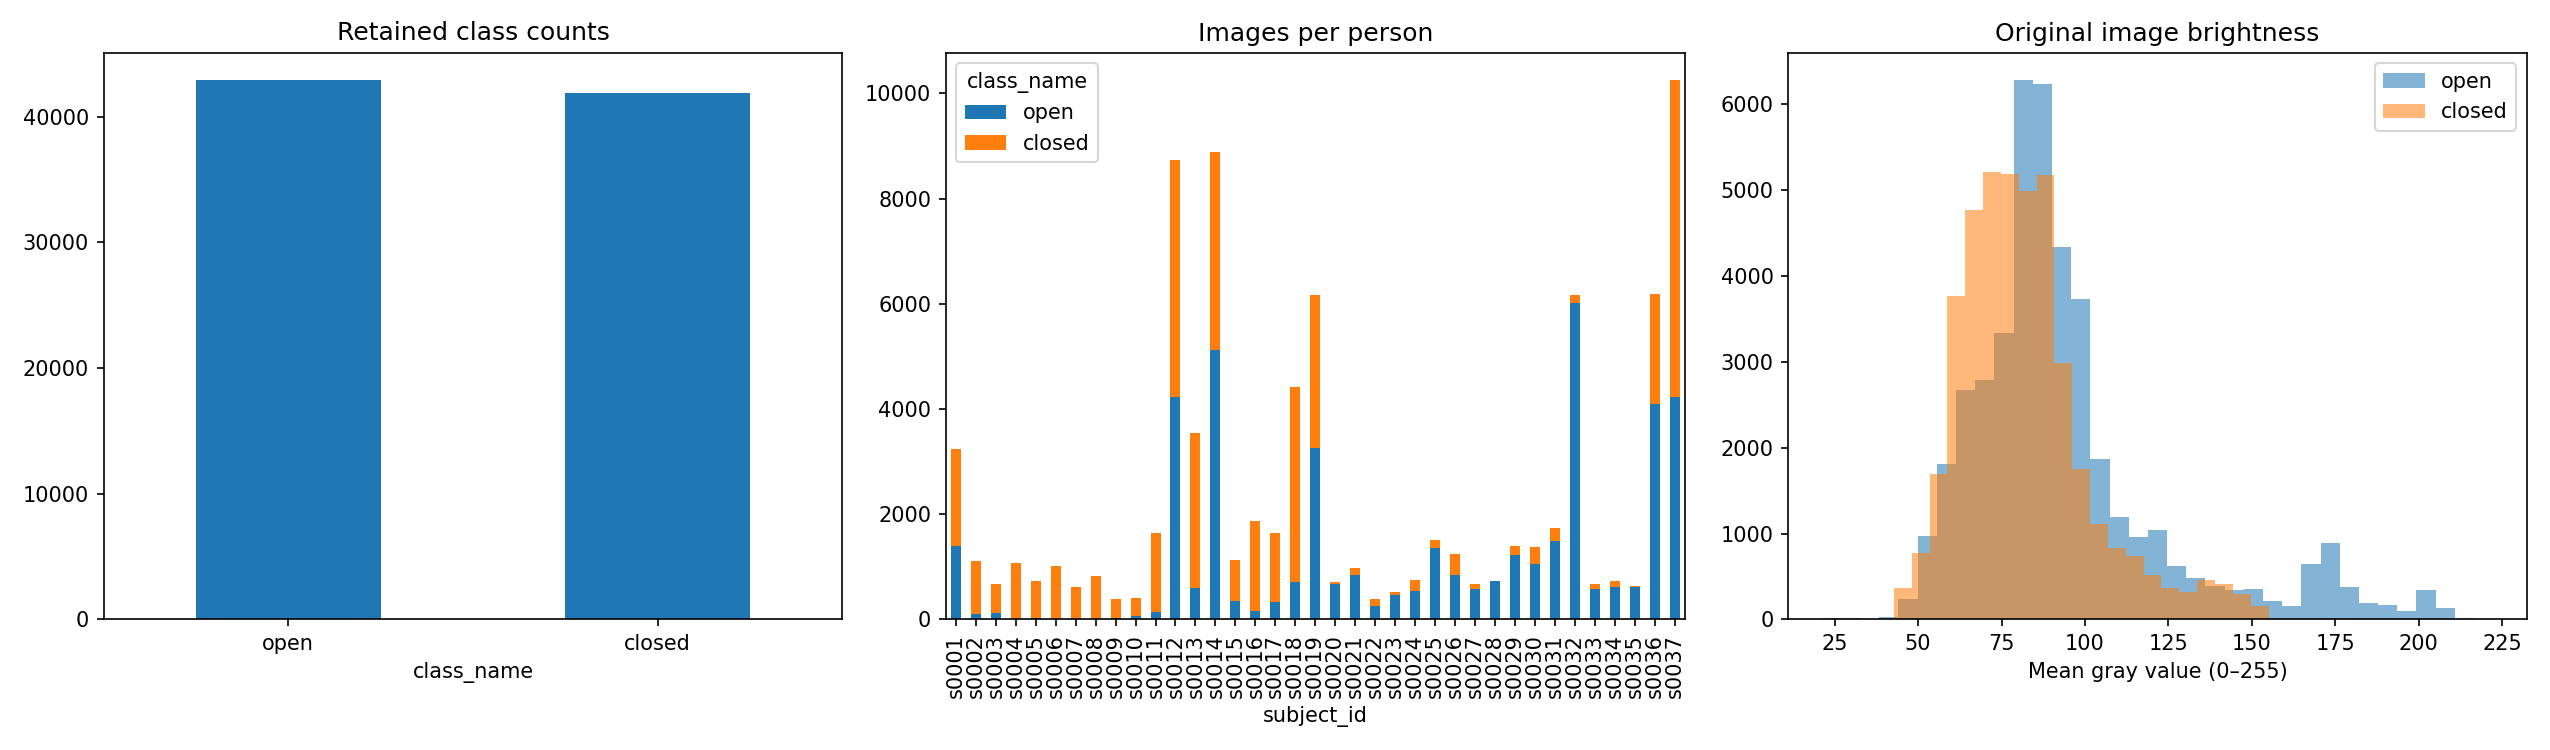

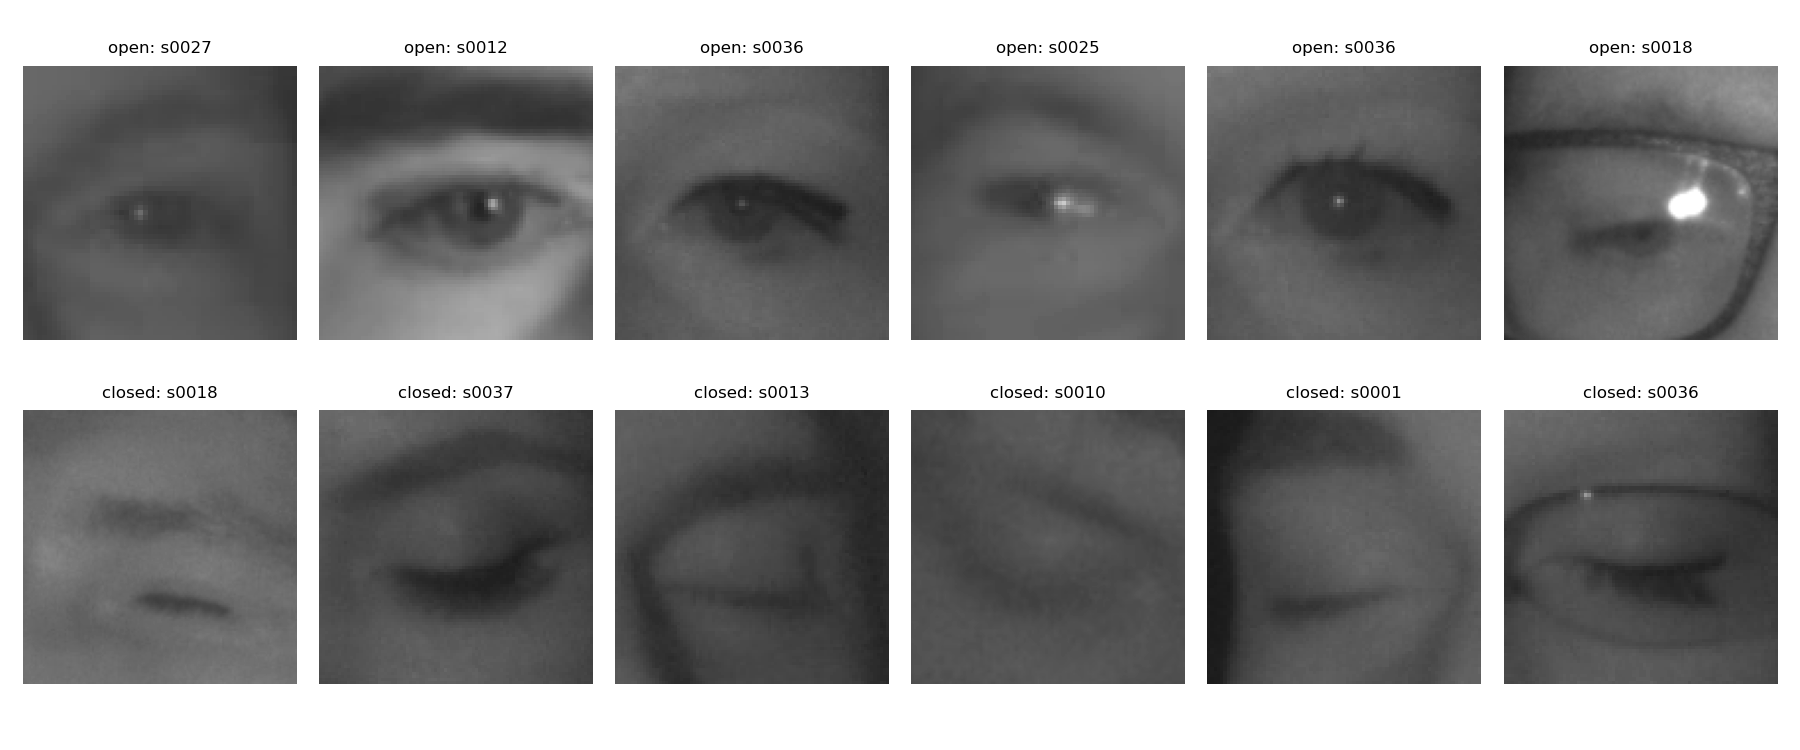

In [3]:
DATASET_READY = SPLIT_READY = MODEL_READY = EVALUATION_READY = EXPORT_READY = False
if CONFIG_READY:
    try:
        dataset, issues = scan_dataset(DATA_DIR, conflict_policy="exclude_all")
    except (FileNotFoundError, ValueError) as exc:
        print("Training pending:", exc)
    else:
        eda = save_eda(dataset, issues, REPORT_DIR, source_root=DATA_DIR)
        display(pd.DataFrame([eda["class_counts"]]))
        display(pd.crosstab(dataset.subject_id, dataset.class_name))
        display(dataset.groupby("class_name").brightness.describe())
        display(issues.head(20))
        display(Image(filename=str(REPORT_DIR / "eda_overview.png")))
        display(Image(filename=str(REPORT_DIR / "sample_grid.png")))
        DATASET_READY = True
else:
    print("EDA pending: environment/configuration is not ready.")


## 3. Reserve test people before model selection

With unsplit data, GroupShuffleSplit reserves approximately 20% of people for testing.
Predefined partitions must also have disjoint people. The test set remains at its original
retained size; only the development pool may be capped for CPU cost. GroupKFold validation
folds contain different people from their training fold. The scaler and augmentation never
see validation/test observations during fitting.


In [4]:
SPLIT_READY = MODEL_READY = EVALUATION_READY = EXPORT_READY = False
if DATASET_READY:
    development_all, test = split_people(dataset, seed=SEED, cv_folds=CV_FOLDS)
    development = sample_development(development_all, CAP_PER_PERSON_CLASS, SEED)
    manifest = pd.concat(
        [development_all.assign(split="development"), test.assign(split="test")],
        ignore_index=True,
    )
    manifest["used_for_fit"] = manifest.path.isin(development.path)
    manifest.to_csv(REPORT_DIR / "split_manifest.csv", index=False)
    display(
        manifest.groupby("split").agg(
            images=("path", "size"), people=("subject_id", "nunique")
        )
    )
    print("Development used:", len(development), "of", len(development_all))
    print("Held-out test people:", sorted(test.subject_id.unique()))
    SPLIT_READY = True
else:
    print("Split skipped: labeled subject data is not ready.")


,images,people
split,,
development,60685,29
test,24142,8


Development used: 5107 of 60685
Held-out test people: ['s0005', 's0007', 's0014', 's0018', 's0026', 's0027', 's0030', 's0036']


## 4. Train and tune using GroupKFold

Shared preprocessing: grayscale → 64×32 resize → histogram equalization → 756 HOG features.
A StandardScaler is fitted only on each fold's training features. Tune C, class weighting,
and whether mild horizontal-flip/rotation augmentation helps. Augmented samples used for fitting are selected
only from that fold's training originals; validation and test always use original images.

Five C values × two class-weight settings × two augmentation settings = 20 configurations,
evaluated in five person-separated folds. Select by mean validation balanced accuracy (then
F1), considering only configurations converged in every fold. `max_iter=20000`, `tol=1e-4`.
Refit the selected model on development data only. Test data is not used for selection.


In [5]:
MODEL_READY = EVALUATION_READY = EXPORT_READY = False
if SPLIT_READY:
    model, selected_params, cv_folds, cv_summary, cv_membership = train_group_cv(
        development, folds=CV_FOLDS, seed=SEED
    )
    cv_folds.to_csv(REPORT_DIR / "cv_fold_results.csv", index=False)
    cv_summary.to_csv(REPORT_DIR / "validation_trials.csv", index=False)
    cv_membership.to_csv(REPORT_DIR / "cv_membership.csv", index=False)
    display(cv_summary.sort_values("mean_balanced_accuracy", ascending=False))
    print("Selected settings:", selected_params)
    MODEL_READY = True
else:
    print("Training skipped: person-separated development data is not ready.")


GroupKFold 1/5 complete (67.6s)
GroupKFold 2/5 complete (125.4s)
GroupKFold 3/5 complete (195.1s)
GroupKFold 4/5 complete (258.4s)
GroupKFold 5/5 complete (329.9s)


,C,class_weight,augmentation,mean_balanced_accuracy,std_balanced_accuracy,mean_f1,mean_roc_auc,all_converged
0,0.001,balanced,False,0.789172,0.046583,0.794574,0.874066,True
2,0.001,none,False,0.788139,0.045164,0.793768,0.873856,True
1,0.001,balanced,True,0.788020,0.044762,0.797110,0.874762,True
3,0.001,none,True,0.787492,0.043511,0.796937,0.874463,True
7,0.010,none,True,0.779513,0.043646,0.790928,0.865044,True
5,0.010,balanced,True,0.778545,0.043263,0.789839,0.865255,True
11,0.100,none,True,0.776715,0.043917,0.788155,0.861503,True
9,0.100,balanced,True,0.775239,0.044310,0.786543,0.861719,True
15,1.000,none,True,0.775052,0.044596,0.786641,0.860882,True
19,10.000,none,True,0.775052,0.044596,0.786641,0.860805,True


Selected settings: {'C': 0.001, 'class_weight': 'balanced', 'augmentation': False}


Selected settings: {'C': 0.001, 'class_weight': 'balanced', 'augmentation': False}


## 5. Evaluate held-out people and export

Report accuracy, balanced accuracy, closed-eye precision/recall/F1, ROC-AUC, per-class
metrics, confusion matrix, ROC plot, sample predictions, and metrics per person. For MRL,
subgroup tables also cover glasses, lighting, sensor, and gender. Small subgroups and
correlated frames require caution; these are not independent-trial confidence estimates.
Compare with a majority-class baseline on exactly the same test images.

Export the compatible NPZ only after numeric inference parity is verified. Streamlit can
load it without changing its existing interface. The model/report fingerprint detects stale
results. Original project and PyImageSearch credits remain in the README.


,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc
0,HOG + linear SVM,0.877144,0.878368,0.842155,0.918845,0.878830,0.953306
1,Majority baseline,0.484881,0.500000,0.484881,1.000000,0.653091,0.500000


,precision,recall,f1-score,support
open,0.916447,0.837890,0.875410,12436.000000
closed,0.842155,0.918845,0.878830,11706.000000
accuracy,0.877144,0.877144,0.877144,0.877144
macro avg,0.879301,0.878368,0.877120,24142.000000
weighted avg,0.880424,0.877144,0.877068,24142.000000


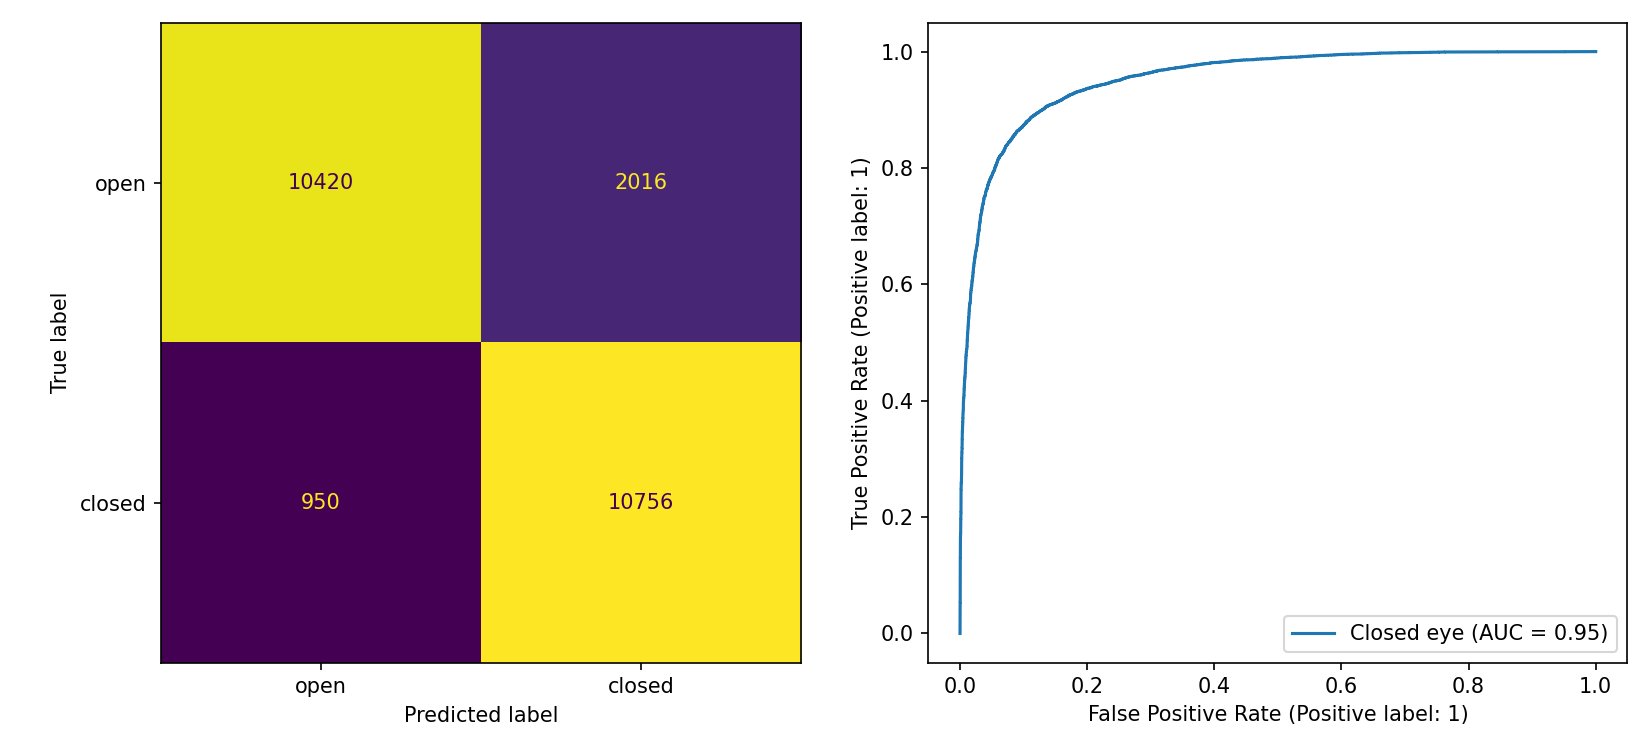

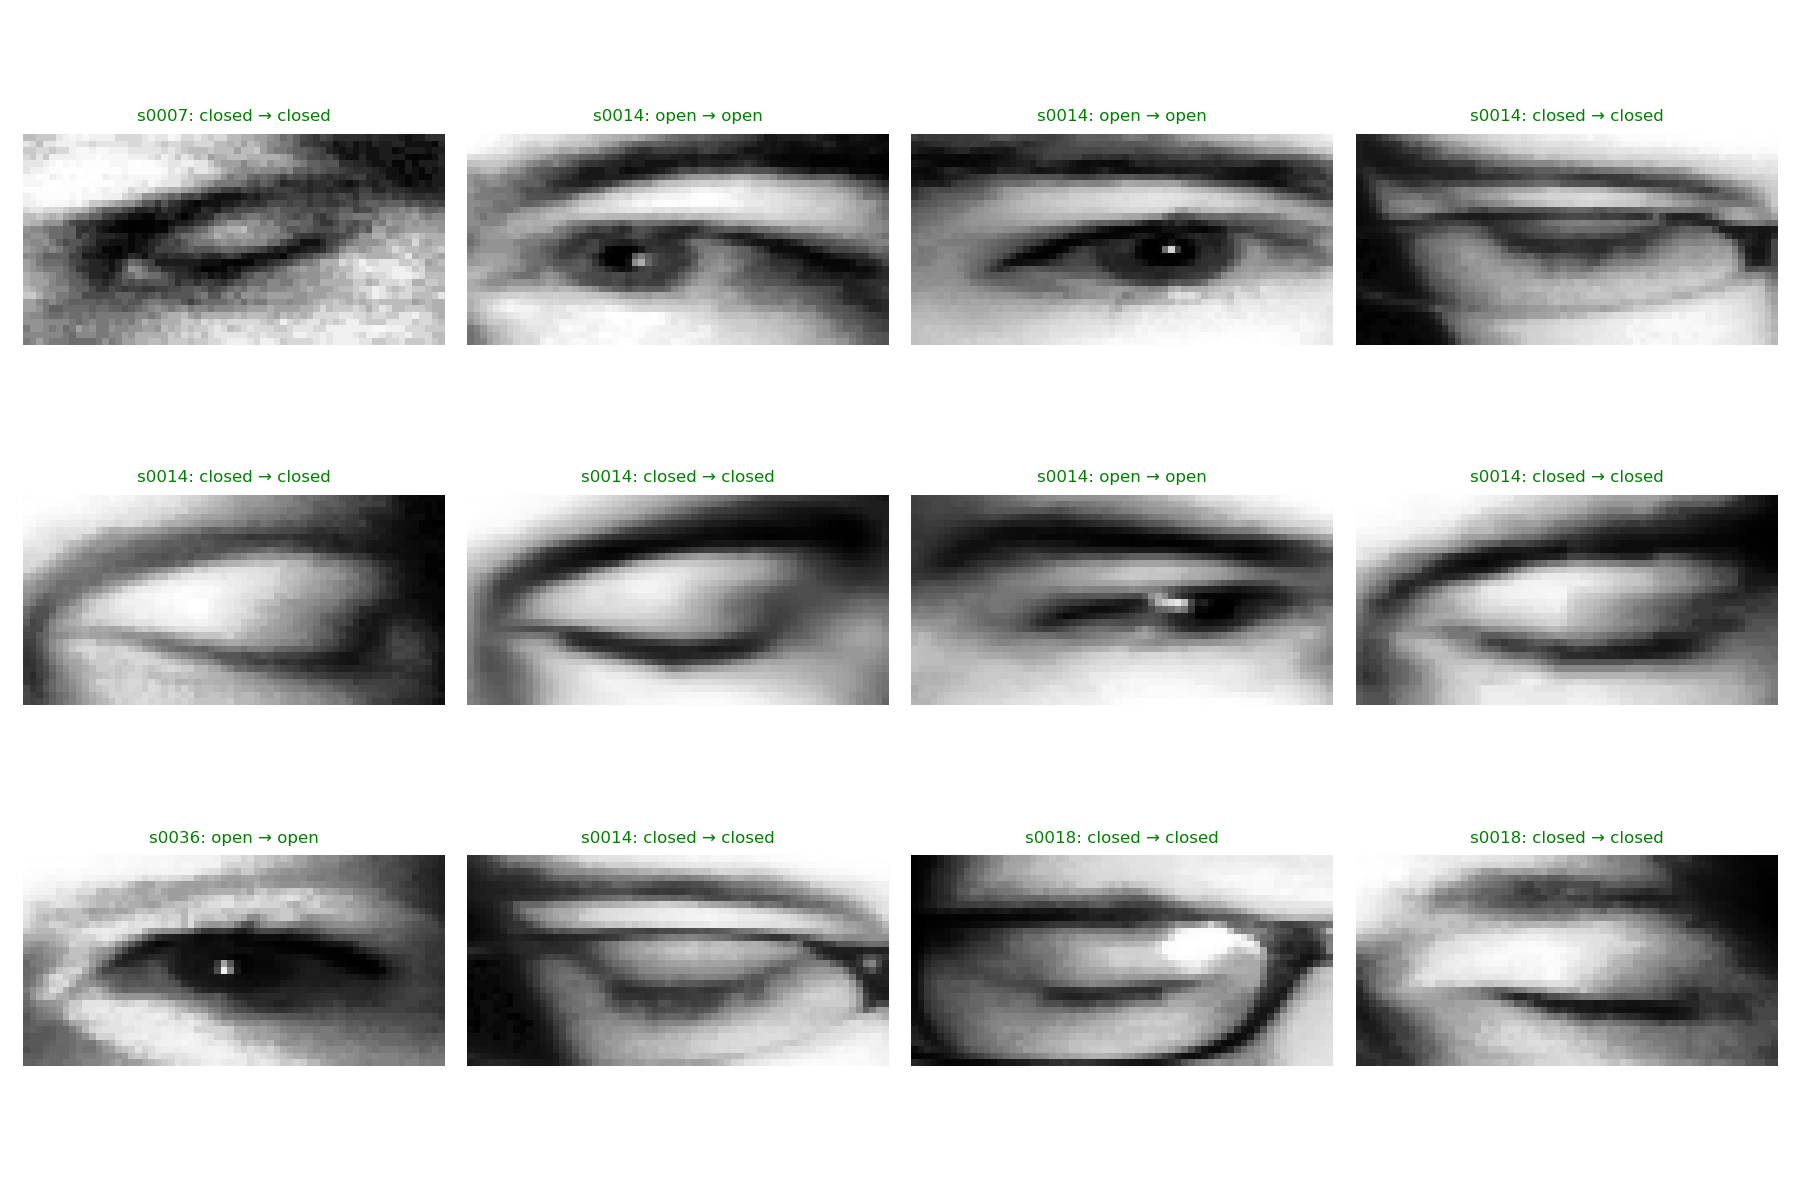

Saved: /home/lokesh-sharma/Documents/Projects/Drowsiness-Detection/models/eye_state_model.npz
Reports: /home/lokesh-sharma/Documents/Projects/Drowsiness-Detection/reports


In [6]:
EVALUATION_READY = EXPORT_READY = False
if MODEL_READY:
    import hashlib

    fingerprint = hashlib.sha256(
        "\n".join(sorted(dataset.relative_path + ":" + dataset.sha256)).encode()
    ).hexdigest()
    context = {
        "seed": SEED,
        "split_protocol": "Person-held-out test; GroupKFold on development only",
        "cv_folds": CV_FOLDS,
        "training_cap_per_person_class": CAP_PER_PERSON_CLASS,
        "development_available": len(development_all),
        "dataset_retained": len(dataset),
        "dataset_fingerprint": fingerprint,
        "test_downsampled": False,
    }
    metrics, comparison = evaluate_and_export(
        model,
        selected_params,
        development,
        test,
        REPORT_DIR,
        MODEL_DIR,
        cv_summary,
        context,
    )
    display(comparison)
    display(pd.DataFrame(metrics["classification_report"]).T)
    display(Image(filename=str(REPORT_DIR / "confusion_matrix.png")))
    display(Image(filename=str(REPORT_DIR / "example_predictions.png")))
    print("Saved:", MODEL_DIR / "eye_state_model.npz")
    print("Reports:", REPORT_DIR)
    EVALUATION_READY = EXPORT_READY = True
else:
    print("Evaluation/export skipped: no model trained in this run.")


## 6. Matched SVM versus EAR and separate video evaluation

MRL supplies individual eye crops. The current dlib EAR detector expects a full face with
landmarks. An EAR score on those isolated crops would not be a valid comparison. The report
therefore records **not_run** with the missing-input reason instead of inventing EAR scores.

For a fair comparison, supply a labeled full-face benchmark CSV with `path`, `subject_id`,
`split` (`validation` or `test`), and `label` (`0` both eyes open / `1` both eyes closed).
Use `compare_methods.py` to evaluate both methods on the same detectable frames, tune the
EAR threshold on validation people only, and report detection coverage separately.
Never use these test people for classifier training or threshold calibration.

Full-video evaluation additionally needs held-out drivers, media timestamps, and human-labeled
closure intervals / drowsiness events. Measure false alerts per minute, missed events, and
alert latency separately from eye classification accuracy. No labeled full-video benchmark is
currently supplied; `video_evaluation.json` records that this test has not run.


In [7]:
if EXPORT_READY:
    for name in ("ear_comparison", "video_evaluation"):
        display(json.loads((REPORT_DIR / f"{name}.json").read_text()))
    print(
        "Eye-state experiment complete. Video drowsiness accuracy is not established."
    )
else:
    print(
        "Run incomplete: supply valid data / finish the preceding stages, then Run All."
    )


{'status': 'not_run',
 'reason': 'Not run: MRL supplies eye crops; the existing dlib EAR pipeline needs labeled full-face samples shared with SVM.'}

{'status': 'not_run',
 'reason': 'Not run: no independent full videos with closure/event ground truth have been supplied.'}

Eye-state experiment complete. Video drowsiness accuracy is not established.


## References

- [MRL Eye Dataset](https://mrl.cs.vsb.cz/eyedataset.html), Radovan Fusek / MRL.
- [GroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html).
- [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html).
- [Original Driver Drowsiness Detector](https://github.com/mohitwildbeast/Driver-Drowsiness-Detector).
- EAR implementation in this project is credited to Adrian Rosebrock's PyImageSearch tutorial.


## Saved real experiment results

This independent read-only cell displays the last completed experiment saved by the CLI or
the notebook. It does not train a model or recompute test scores. Its saved output is from
the real MRL run, not the synthetic test fixtures used to verify the notebook.


| Held-out eye-state metric | Value |
| --- | --- |
| accuracy | 0.877144 |
| balanced_accuracy | 0.878368 |
| precision | 0.842155 |
| recall | 0.918845 |
| f1 | 0.878830 |
| roc_auc | 0.953306 |

Run timestamp: 2026-11-26T21:54:01.072479+00:00
Development originals used: 5107
Test originals: 24142
Held-out people: ['s0005', 's0007', 's0014', 's0018', 's0026', 's0027', 's0030', 's0036']
Selected settings: {'C': 0.001, 'class_weight': 'balanced', 'augmentation': False}
Development cap/person/class: 100
This is eye classification, not video drowsiness accuracy.


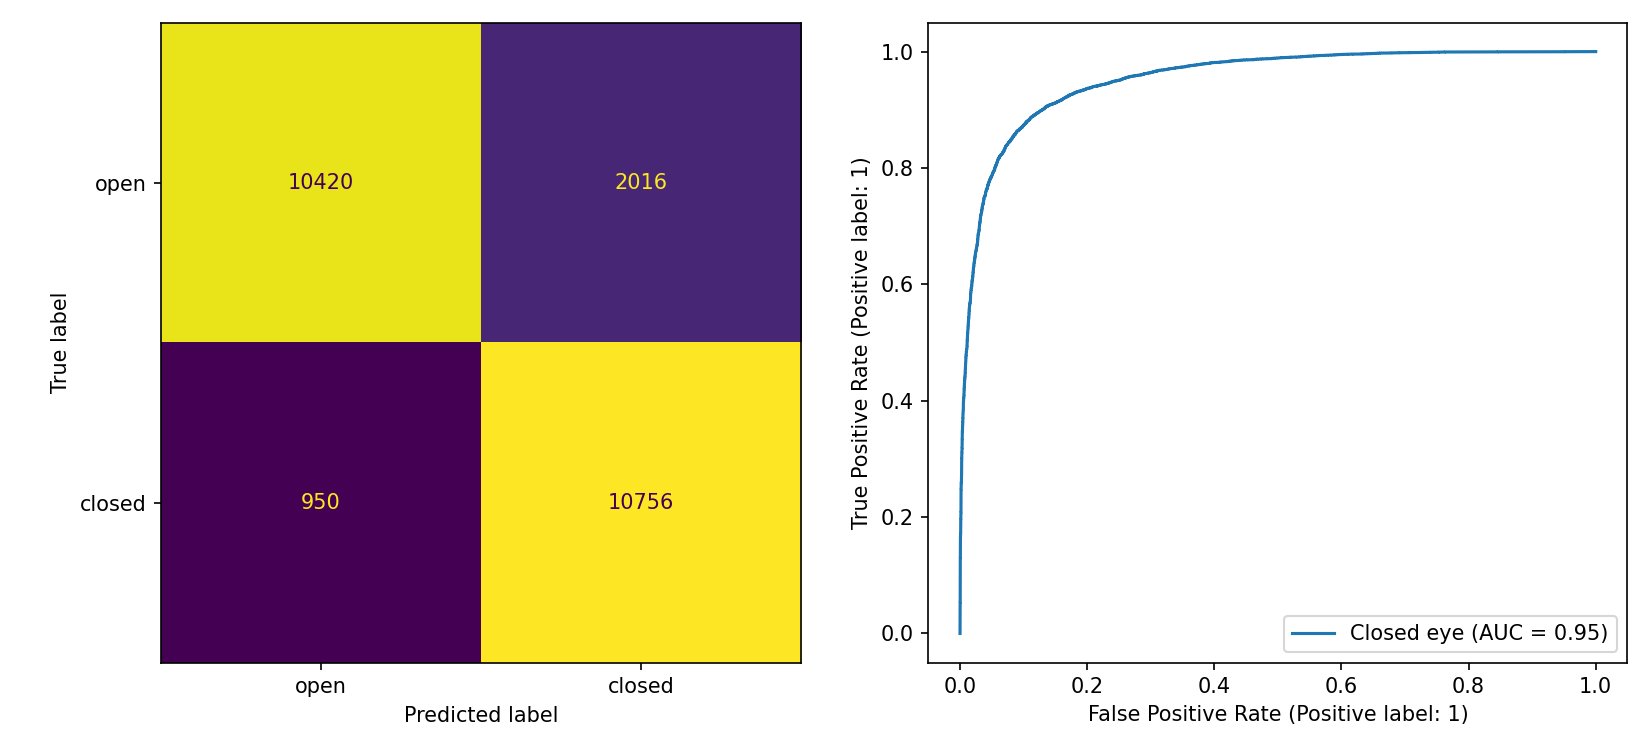

In [8]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image

saved_output = Path(globals().get("OUTPUT_DIR", Path.cwd()))
saved_metrics_path = saved_output / "reports/metrics.json"
if saved_metrics_path.exists():
    saved_metrics = json.loads(saved_metrics_path.read_text())
    lines = ["| Held-out eye-state metric | Value |", "| --- | --- |"]
    for key in (
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
    ):
        lines.append(f"| {key} | {saved_metrics[key]:.6f} |")
    display(Markdown("\n".join(lines)))
    print("Run timestamp:", saved_metrics["created_utc"])
    print("Development originals used:", saved_metrics["counts"]["development_used"])
    print("Test originals:", saved_metrics["counts"]["test"])
    print("Held-out people:", saved_metrics["test_people"])
    print("Selected settings:", saved_metrics["selected_params"])
    print(
        "Development cap/person/class:",
        saved_metrics.get("training_cap_per_person_class"),
    )
    print("This is eye classification, not video drowsiness accuracy.")
    display(Image(filename=str(saved_output / "reports/confusion_matrix.png")))
else:
    print(
        "No completed experiment is saved here yet. Run training with real labeled data first."
    )
